In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss

# Membaca dataset
df = pd.read_excel('/content/Temperatur_Surabaya_2022-2024.xlsx')

# Mengurutkan nama bulan
urutan_bulan = [
    'Januari', 'Februari', 'Maret', 'April',
    'Mei', 'Juni', 'Juli', 'Agustus',
    'September', 'Oktober', 'November', 'Desember'
]

df['Bulan'] = pd.Categorical(
    df['Bulan'],
    categories=urutan_bulan,
    ordered=True
)

df = df.sort_values(['Tahun', 'Bulan']).reset_index(drop=True)

# Membuat indeks waktu bulanan
df['Tanggal'] = pd.to_datetime(
    df['Tahun'].astype(str) + '-' +
    (df['Bulan'].cat.codes + 1).astype(str) + '-01'
)

df = df.set_index('Tanggal')

# Memilih variabel temperatur
kolom_temperatur = [
    'Minimum (°C)',
    'Rata-rata (°C)',
    'Maksimum (°C)'
]

df[kolom_temperatur].head()

,Minimum (°C),Rata-rata (°C),Maksimum (°C)
Tanggal,,,
2022-01-01,23.8,27.7,35.5
2022-02-01,22.5,27.4,34.0
2022-03-01,23.0,28.1,35.0
2022-04-01,23.2,28.9,34.8
2022-05-01,23.2,29.0,34.8


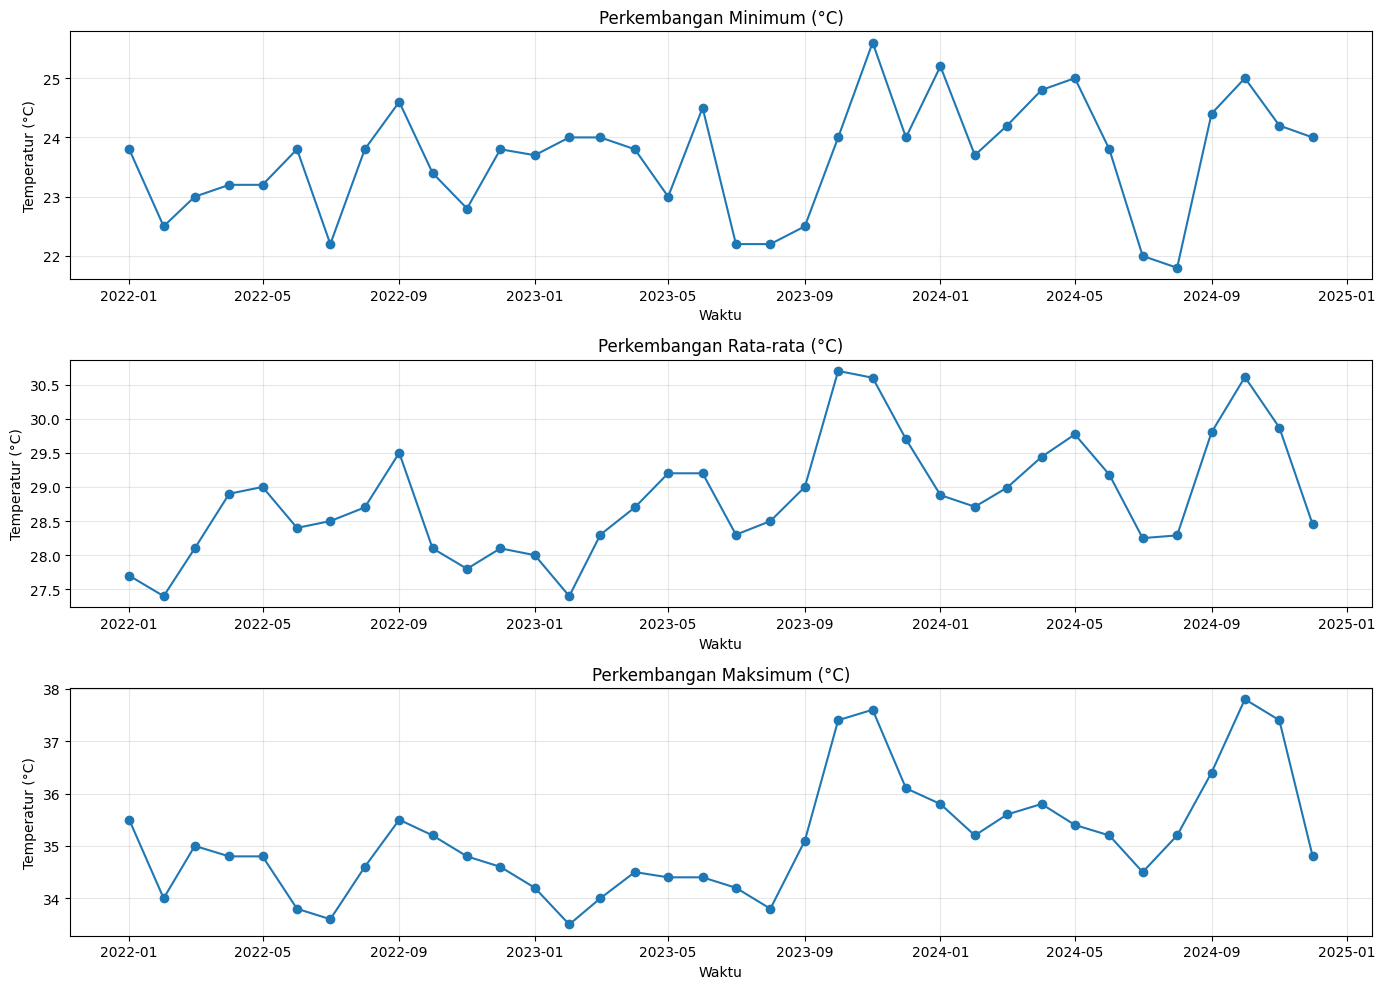

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for i, kolom in enumerate(kolom_temperatur):
    axes[i].plot(
        df.index,
        df[kolom],
        marker='o',
        linewidth=1.5
    )

    axes[i].set_title(f'Perkembangan {kolom}')
    axes[i].set_ylabel('Temperatur (°C)')
    axes[i].set_xlabel('Waktu')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

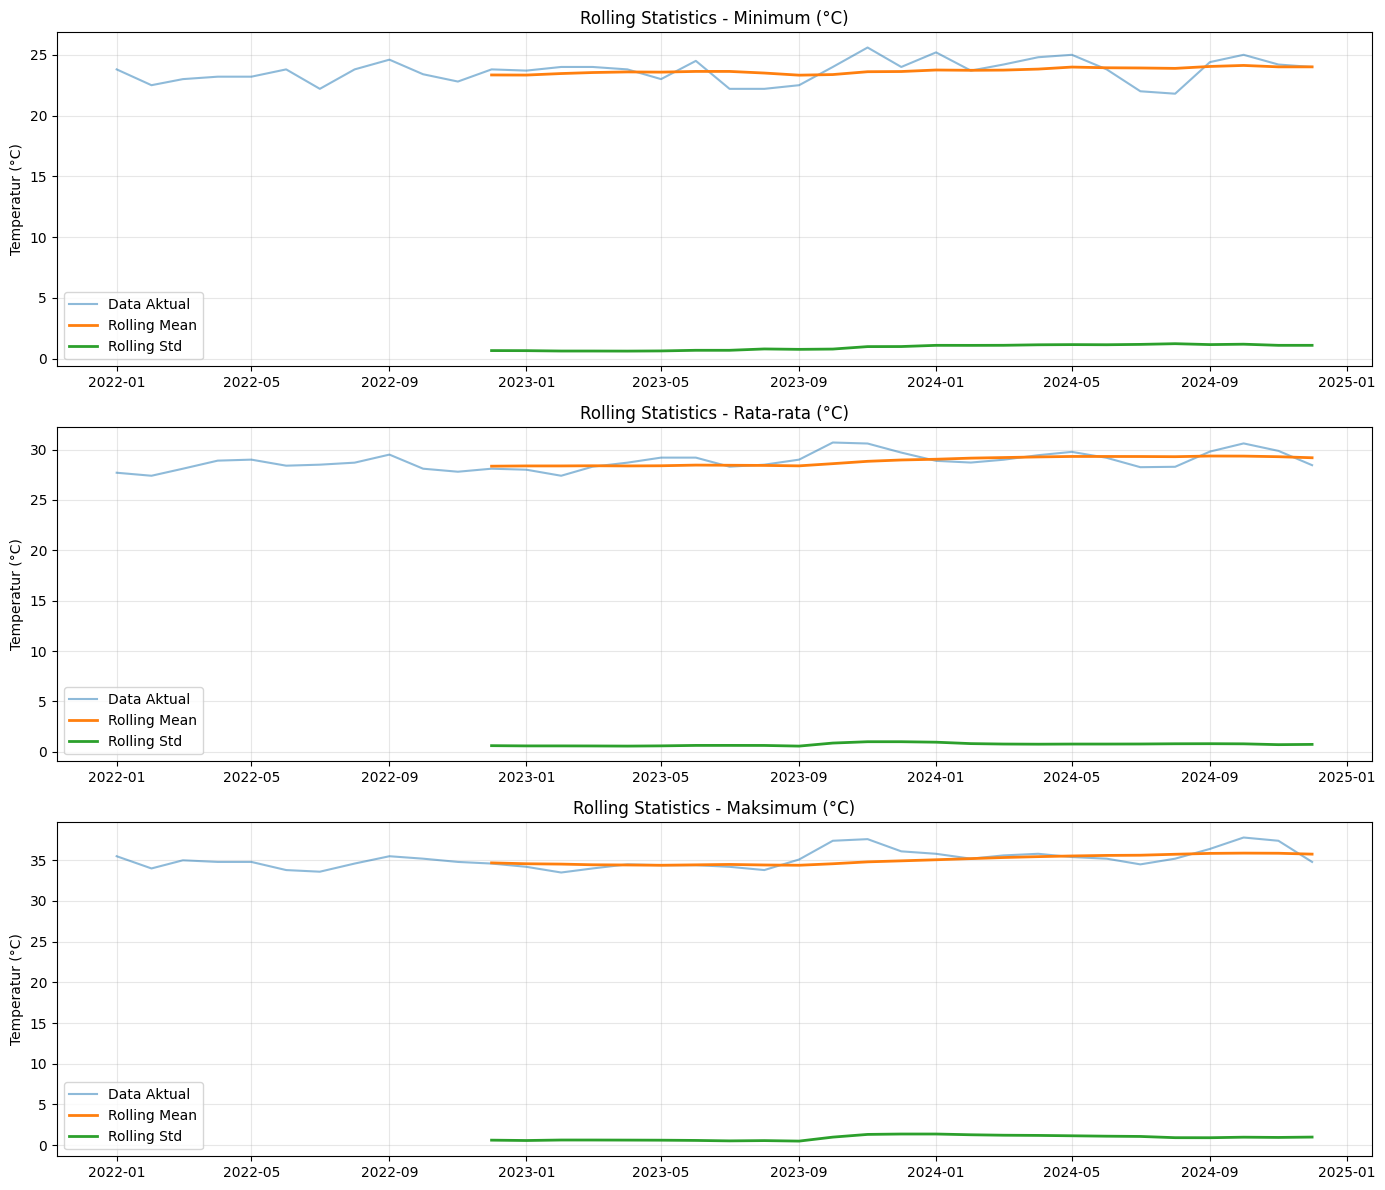

In [4]:
window = 12

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for i, kolom in enumerate(kolom_temperatur):

    rolling_mean = df[kolom].rolling(window=window).mean()
    rolling_std = df[kolom].rolling(window=window).std()

    axes[i].plot(
        df.index,
        df[kolom],
        label='Data Aktual',
        alpha=0.5
    )

    axes[i].plot(
        df.index,
        rolling_mean,
        label='Rolling Mean',
        linewidth=2
    )

    axes[i].plot(
        df.index,
        rolling_std,
        label='Rolling Std',
        linewidth=2
    )

    axes[i].set_title(f'Rolling Statistics - {kolom}')
    axes[i].set_ylabel('Temperatur (°C)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
def uji_stasioneritas(data, nama_variabel):
    hasil = []

    for kolom in nama_variabel:
        series = data[kolom].dropna()

        # Augmented Dickey-Fuller Test
        adf_result = adfuller(
            series,
            regression='c',
            autolag='AIC'
        )

        # KPSS Test
        kpss_result = kpss(
            series,
            regression='c',
            nlags='auto'
        )

        hasil.append({
            'Variabel': kolom,
            'ADF Statistic': adf_result[0],
            'ADF p-value': adf_result[1],
            'KPSS Statistic': kpss_result[0],
            'KPSS p-value': kpss_result[1],
            'Kesimpulan ADF': (
                'Stasioner' if adf_result[1] < 0.05
                else 'Tidak Stasioner'
            ),
            'Kesimpulan KPSS': (
                'Stasioner' if kpss_result[1] > 0.05
                else 'Tidak Stasioner'
            )
        })

    return pd.DataFrame(hasil)


# Menjalankan pengujian
hasil_uji = uji_stasioneritas(
    df,
    kolom_temperatur
)

# Menampilkan hasil
pd.set_option('display.max_columns', None)
display(hasil_uji.round(4))

/tmp/ipykernel_604/3720953228.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_604/3720953228.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_604/3720953228.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or

,Variabel,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,Kesimpulan ADF,Kesimpulan KPSS
0,Minimum (°C),-4.1369,0.0008,0.2485,0.1000,Stasioner,Stasioner
1,Rata-rata (°C),-1.6454,0.4594,0.5855,0.0240,Tidak Stasioner,Tidak Stasioner
2,Maksimum (°C),-2.6152,0.0899,0.4960,0.0426,Tidak Stasioner,Tidak Stasioner


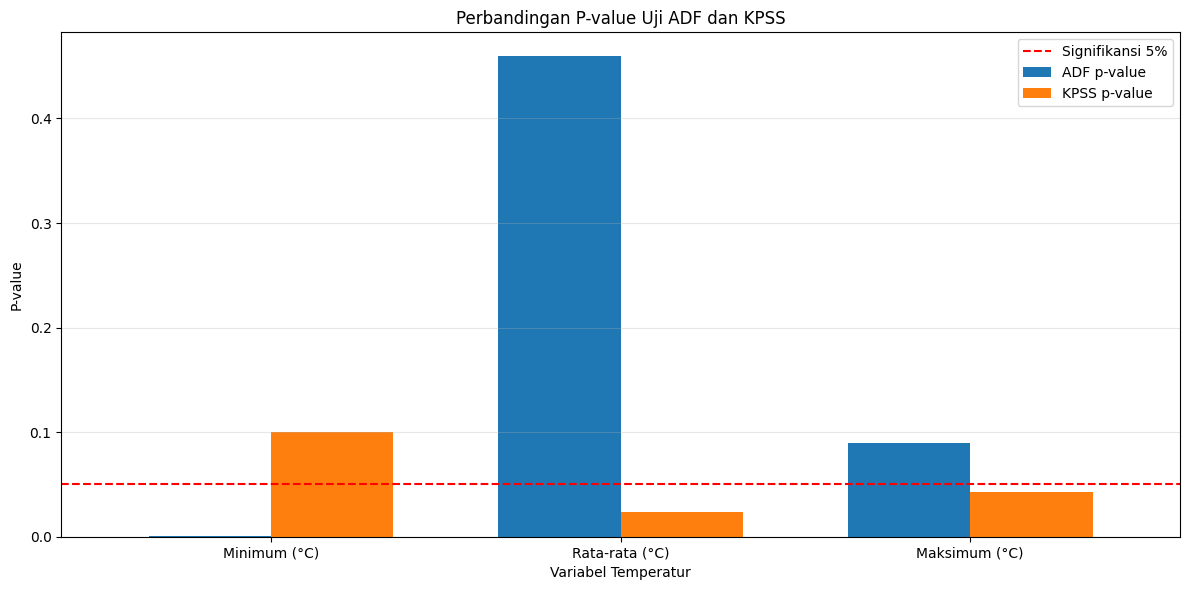

In [6]:
hasil_plot = hasil_uji.set_index('Variabel')[
    ['ADF p-value', 'KPSS p-value']
]

ax = hasil_plot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.7
)

ax.axhline(
    y=0.05,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Signifikansi 5%'
)

ax.set_title('Perbandingan P-value Uji ADF dan KPSS')
ax.set_ylabel('P-value')
ax.set_xlabel('Variabel Temperatur')
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()